# 0210 · Análisis exploratorio v3 sobre la base por guía (OE1)

**Qué hace.** Caracteriza los factores asociados al tiempo de última milla y al incumplimiento de SLA sobre la base v3 de `0330_BaseAnaliticaV3` (una fila por guía, T0 = primera salida a zona urbana). Reemplaza el exploratorio de `0200`, que usaba solo enero, la base antigua y el primer proceso 9 (realimentación S6).

**Reglas que sigue.**
- **Solo periodo de desarrollo** (T0 antes de `FIN_DESARROLLO`): julio y agosto quedan reservados para la prueba final y no se miran aquí.
- **Cada tasa con su denominador** (`n`) y su intervalo de confianza del 95 % (Wilson). Los grupos con menos de `N_MIN` guías no se muestran.
- **Solo agregados**: no se muestra ninguna guía individual.
- Las asociaciones son **descriptivas, no causales**.

**Requisitos.** `V3/GOLD_V3_ENVIO.parquet` aprobada en `0330_BaseAnaliticaV3`. Opcional: `GOLD_V3_ENVIO_CLIMA.parquet` de `0160` para la sección de clima.

**Salidas.** CSV y PNG en `REVISION_2026_10/V3/EDA/`. Lo que se entrega está al final.

> **Cambios frente a la v2 (21-10-2026).**
> - Lee la base v3 (SLA en días hábiles, una fila de RED por regla, devoluciones y siniestros aparte).
> - La población principal es `origen_sla` en `SLA_UNICO` o `SLA_POR_REGLA` (antes, solo `SLA_PARAMETRIZADO`), sin devoluciones ni siniestros. Solo `SLA_UNICO` queda como sensibilidad.
> - La celda de carga (sección 1) vuelve a estar activa: en la corrida del 20-10 quedó comentada y el cuaderno se detuvo con `NameError: dev`.
> - `cargar_festivos` es la versión que el equipo ajustó en `0410` (la columna de festivos ya trae las fechas), para que los dos cuadernos marquen los mismos días.
> - Se excluyen `guia` e `ID_CLIENTE` al cargar: este cuaderno no necesita identificadores.

In [0]:
# Si faltan librerías:
# %pip install duckdb matplotlib

In [0]:
%pip install "duckdb<2"
dbutils.library.restartPython()

Looking in indexes: [REDACTED]
Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


In [0]:
# CONFIGURACIÓN
import os, numpy as np, pandas as pd, duckdb, matplotlib.pyplot as plt
PATH_DATABRICKS = "/Volumes/proyectogrado/source/source/"
CARPETA_SALIDAS = f"{PATH_DATABRICKS}LOG_CONSOLIDADO/REVISION_2026_10/V3/"   # v3: carpeta propia, no pisa la v2
CARPETA_EDA     = f"{CARPETA_SALIDAS}EDA/"
os.makedirs(CARPETA_EDA, exist_ok=True)
RUTA_GOLD_V3       = f"{CARPETA_SALIDAS}GOLD_V3_ENVIO.parquet"          # 0330
RUTA_GOLD_V3_CLIMA = f"{CARPETA_SALIDAS}GOLD_V3_ENVIO_CLIMA.parquet"    # 0160 (opcional)
RUTA_CALENDARIO    = f"{PATH_DATABRICKS}PARAMETRICAS/DIM.VW_TIEMPO_CALENDARIO_Y_FESTIVOS.parquet"

FIN_DESARROLLO = "2026-07-01"   # igual que en 0410: desde aquí es prueba final y no se explora
N_MIN = 30                      # grupos más pequeños no se muestran
SLA_PRINCIPAL = ["SLA_UNICO", "SLA_POR_REGLA"]   # v3: población principal; sensibilidad: solo SLA_UNICO
# Columnas del calendario: None = detección automática; si falla, escribir aquí sus nombres
COL_FECHA_CAL, COL_FESTIVO = None, None

## Funciones (no es necesario modificarlas)

In [0]:
def cargar_festivos(ruta, col_fecha=None, col_festivo=None):
    """Fechas festivas desde DIM.VW_TIEMPO_CALENDARIO_Y_FESTIVOS donde la columna de festivos ya contiene las fechas."""
    cal = pd.read_parquet(ruta)
    cols = list(cal.columns)
    
    if col_fecha is None:
        cand = [c for c in cols if "FECHA" in c.upper() and pd.api.types.is_datetime64_any_dtype(cal[c])] or \
               [c for c in cols if "FECHA" in c.upper()]
        col_fecha = cand[0] if cand else None
        
    if col_festivo is None:
        cand = [c for c in cols if "FESTIV" in c.upper() and "FECHA" not in c.upper()]
        if not cand:
            cand = [c for c in cols if "FESTIV" in c.upper()]
        col_festivo = cand[0] if cand else None
        
    if col_fecha is None or col_festivo is None:
        raise ValueError(f"No se identificaron fecha/festivo. Columnas: {cols}.")
    
    # Como la columna col_festivo ya contiene las fechas de los días festivos y NaT en los demás días,
    # solo necesitamos limpiar los valores nulos (NaT) y normalizar las fechas.
    v = cal[col_festivo]
    f = set(pd.to_datetime(v.dropna()).dt.normalize())
    
    assert len(f) > 0, f"El calendario no marca ningún festivo en la columna '{col_festivo}'"
    print(f"Festivos cargados exitosamente: {len(f)} (columnas: '{col_fecha}', '{col_festivo}')")
    return f

def wilson(k, n, z=1.96):
    k, n = np.asarray(k, float), np.asarray(n, float)
    p = np.divide(k, n, out=np.full_like(k, np.nan), where=n > 0)
    den = 1 + z**2 / n
    centro = (p + z**2 / (2 * n)) / den
    medio = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / den
    return centro - medio, centro + medio

def perfil(df, por, n_min=N_MIN, orden=None):
    """Por grupo: guías, tasa de incumplimiento con IC95 (solo etiquetadas) y cuantiles de última milla."""
    g = df.groupby(por, observed=True, dropna=False)
    t = pd.DataFrame({
        "guias": g.size(),
        "n_etiquetadas": g["incumplimiento_sla"].count(),
        "incumplidas": g["incumplimiento_sla"].sum(),
        "n_con_ultima_milla": g["h_ultima_milla"].count(),
        "mediana_h": g["h_ultima_milla"].median(),
        "p90_h": g["h_ultima_milla"].quantile(0.9),
    })
    t["tasa_incumplimiento"] = t.incumplidas / t.n_etiquetadas
    t["ic95_inf"], t["ic95_sup"] = wilson(t.incumplidas, t.n_etiquetadas)
    t["pct_guias"] = t.guias / t.guias.sum()
    t = t[t.guias >= n_min]
    t = t.sort_index() if orden is None else t.sort_values(orden, ascending=False)
    return t.round(4)

def guardar(t, nombre):
    t.to_csv(f"{CARPETA_EDA}{nombre}.csv")

def grafico_tasa(t, titulo, nombre, rot=0):
    fig, ax = plt.subplots(figsize=(max(6, 0.45 * len(t) + 2), 3.6))
    x = np.arange(len(t))
    ax.bar(x, t.tasa_incumplimiento, color="#4C78A8")
    ax.errorbar(x, t.tasa_incumplimiento, yerr=[t.tasa_incumplimiento - t.ic95_inf, t.ic95_sup - t.tasa_incumplimiento],
                fmt="none", ecolor="#333", capsize=3, lw=1)
    ax.set_xticks(x); ax.set_xticklabels([str(i) for i in t.index], rotation=rot, ha="right" if rot else "center")
    ax.set_ylabel("Tasa de incumplimiento"); ax.set_title(titulo); ax.set_ylim(0, 1)
    for xi, n in zip(x, t.n_etiquetadas):
        ax.text(xi, 0.02, f"n={int(n):,}", ha="center", va="bottom", fontsize=7, rotation=90, color="white")
    plt.tight_layout(); fig.savefig(f"{CARPETA_EDA}{nombre}.png", dpi=130); plt.show()

## 1. Carga y variables conocidas en T0

In [0]:
festivos = cargar_festivos(RUTA_CALENDARIO, COL_FECHA_CAL, COL_FESTIVO)
usa_clima = os.path.exists(RUTA_GOLD_V3_CLIMA)
ruta = RUTA_GOLD_V3_CLIMA if usa_clima else RUTA_GOLD_V3
todo = duckdb.sql(f"SELECT * EXCLUDE (guia, ID_CLIENTE) FROM read_parquet('{ruta}')").df()   # sin identificadores
for c in ["t0", "FECHA_ENVIO", "fecha_entrega"]:
    todo[c] = pd.to_datetime(todo[c])
todo["entrega_sin_hora"] = todo.fecha_entrega.notna() & (todo.fecha_entrega == todo.fecha_entrega.dt.normalize())
todo["mes_t0"] = todo.t0.dt.to_period("M").astype(str)
todo["hora_t0"] = todo.t0.dt.hour
todo["franja"] = pd.cut(todo.hora_t0, [-1, 5, 11, 17, 23], labels=["MADRUGADA", "MANANA", "TARDE", "NOCHE"]).astype(str)
todo["dia_semana"] = todo.t0.dt.dayofweek.map(dict(enumerate(["1 lun", "2 mar", "3 mié", "4 jue", "5 vie", "6 sáb", "7 dom"])))
todo["festivo_t0"] = todo.t0.dt.normalize().isin(festivos).map({True: "festivo", False: "no festivo"})
todo["piezas_cat"] = pd.cut(todo.piezas_declaradas, [0, 1, 2, 5, np.inf], labels=["1", "2", "3-5", "6+"]).astype(str)
todo["peso_decil"] = pd.qcut(todo.peso_declarado_kg.rank(method="first"), 10, labels=[f"D{i}" for i in range(1, 11)]).astype(str)
todo["margen_cat"] = pd.cut(todo.margen_sla_en_t0_h, [-np.inf, 0, 6, 12, 24, 48, np.inf],
                            labels=["<0 (vencido)", "0-6", "6-12", "12-24", "24-48", ">48"]).astype(str)
print(f"Base completa: {len(todo):,} guías; T0 de {todo.t0.min()} a {todo.t0.max()}; clima: {usa_clima}")
dev = todo[todo.t0 < pd.Timestamp(FIN_DESARROLLO)].copy()
print(f"Periodo de desarrollo (T0 < {FIN_DESARROLLO}): {len(dev):,} guías")

Festivos cargados exitosamente: 404 (columnas: 'FECHA_FESTIVA', 'FECHA_FESTIVA')


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Base completa: 3,051,543 guías; T0 de 2026-01-02 06:58:11 a 2026-08-28 16:20:21; clima: True
Periodo de desarrollo (T0 < 2026-07-01): 2,326,676 guías


## 2. Exclusiones y población de análisis

Cada motivo se cuenta sobre el periodo de desarrollo y **con su tasa de incumplimiento**, para ver si excluir cambia la población. Los motivos no son excluyentes: una guía puede tener varios.

In [0]:
p999 = dev.h_ultima_milla.quantile(0.999)
motivos = {
    "SLA fuera del principal (sustitución o sin SLA)": ~dev.origen_sla.isin(SLA_PRINCIPAL),
    "Devolución o siniestro (desenlace aparte)": dev.estado_desenlace.isin(["DEVUELTO", "SINIESTRADO"]),
    "SLA por regla (clave de RED con plazos distintos; sensibilidad)": dev.origen_sla == "SLA_POR_REGLA",
    "Etiqueta no identificable (abierto sin vencer o sin SLA)": dev.incumplimiento_sla.isna(),
    "Ya vencido antes de T0": dev.vencido_antes_de_t0.fillna(False).astype(bool),
    "Entrega sin hora (00:00:00)": dev.entrega_sin_hora,
    "Última milla negativa": dev.h_ultima_milla < 0,
    f"Última milla > p99,9 ({p999:,.0f} h)": dev.h_ultima_milla > p999,
    "Re-despacho (más de una salida a zona)": dev.n_salidas_zona > 1,
}
filas = []
for m, mask in motivos.items():
    sub = dev[mask]
    filas.append({"motivo": m, "guias": int(mask.sum()), "pct": mask.mean(),
                  "tasa_incumplimiento": sub.incumplimiento_sla.mean(), "n_etiquetadas": sub.incumplimiento_sla.count()})
excl = pd.DataFrame(filas).set_index("motivo").round(4)
display(excl); guardar(excl, "01_exclusiones")

poblacion = (dev.origen_sla.isin(SLA_PRINCIPAL) & ~dev.estado_desenlace.isin(["DEVUELTO", "SINIESTRADO"])
             & ~dev.vencido_antes_de_t0.fillna(False).astype(bool) & ~dev.entrega_sin_hora)
d = dev[poblacion].copy()
d.loc[d.h_ultima_milla < 0, "h_ultima_milla"] = np.nan          # negativas: se auditan, no entran a los cuantiles
print(f"Población de análisis principal: {len(d):,} guías ({len(d)/len(dev):.1%} del desarrollo); "
      f"etiquetadas: {d.incumplimiento_sla.count():,}; prevalencia: {d.incumplimiento_sla.mean():.3f}")
# Sensibilidad: la misma población con solo SLA_UNICO
sens_unico = dev[poblacion & (dev.origen_sla == "SLA_UNICO")]
print(f"Sensibilidad solo SLA_UNICO: {len(sens_unico):,} guías; prevalencia {sens_unico.incumplimiento_sla.mean():.3f}")

guias,pct,tasa_incumplimiento,n_etiquetadas
19141,0.0082,0.39973856209150327,19125
58537,0.0252,null,0
8838,0.0038,0.7522265357387531,8758
58542,0.0252,null,0
1098358,0.4721,0.9995662623122145,1069771
20328,0.0087,0.9346772416831901,18156
9677,0.0042,0.893045365299163,9677
2269,0.001,1.0,2269
153802,0.0661,0.9299426905084952,98762


Población de análisis principal: 1,177,341 guías (50.6% del desarrollo); etiquetadas: 1,177,341; prevalencia: 0.063
Sensibilidad solo SLA_UNICO: 1,175,030 guías; prevalencia 0.063


## 3. Distribución de las variables objetivo

h_ultima_milla (T0 a entrega),h_admision_a_t0 (tránsito previo),h_total (admisión a entrega),sla_h
0.02,-5.99,1.88,24.0
2.02,13.23,18.58,24.0
3.58,17.61,23.05,24.0
5.85,21.2,27.67,24.0
8.88,25.19,37.29,24.0
12.54,47.0,66.49,48.0
100.03,93.84,138.15,96.0
305.28,140.32,336.75,168.0


guias,prevalencia
20,1.0
1177321,0.063371841664253


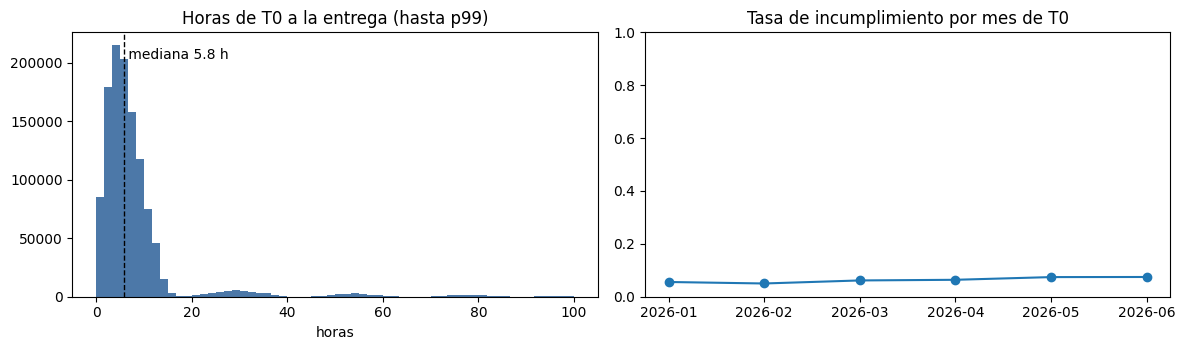

In [0]:
q = [0.01, 0.10, 0.25, 0.50, 0.75, 0.90, 0.99, 0.999]
cuant = pd.DataFrame({
    "h_ultima_milla (T0 a entrega)": d.h_ultima_milla.quantile(q),
    "h_admision_a_t0 (tránsito previo)": d.h_admision_a_t0.quantile(q),
    "h_total (admisión a entrega)": d.h_total.quantile(q),
    "sla_h": d.sla_h.quantile(q)}).round(2)
cuant.index = [f"q{x:g}" for x in q]
display(cuant); guardar(cuant, "02_cuantiles_tiempos")
estado = d.groupby("estado_desenlace").agg(guias=("estado_desenlace", "size"), prevalencia=("incumplimiento_sla", "mean"))
display(estado); guardar(estado, "02b_estado_desenlace")

fig, axs = plt.subplots(1, 2, figsize=(12, 3.6))
x = d.h_ultima_milla.dropna(); x = x[x <= x.quantile(0.99)]
axs[0].hist(x, bins=60, color="#4C78A8"); axs[0].set_title("Horas de T0 a la entrega (hasta p99)"); axs[0].set_xlabel("horas")
axs[0].axvline(x.median(), color="k", ls="--", lw=1); axs[0].text(x.median(), axs[0].get_ylim()[1]*.9, f" mediana {x.median():.1f} h")
m = d.groupby("mes_t0").agg(n=("incumplimiento_sla", "count"), k=("incumplimiento_sla", "sum"), med=("h_ultima_milla", "median"))
lo, hi = wilson(m.k, m.n)
axs[1].errorbar(m.index, m.k / m.n, yerr=[m.k / m.n - lo, hi - m.k / m.n], marker="o", capsize=3)
axs[1].set_title("Tasa de incumplimiento por mes de T0"); axs[1].set_ylim(0, 1)
plt.tight_layout(); fig.savefig(f"{CARPETA_EDA}03_distribucion_y_mes.png", dpi=130); plt.show()

## 4. Perfiles por factor

Factores **temporales**, **espaciales**, **de operación** y **de servicio** conocidos en T0. Cada tabla trae guías, tasa con IC 95 %, mediana y percentil 90 de la última milla.

temporal · mes de T0


guias,n_etiquetadas,incumplidas,n_con_ultima_milla,mediana_h,p90_h,tasa_incumplimiento,ic95_inf,ic95_sup,pct_guias
171218,171218,9539,171200,6.2911,12.2042,0.0557,0.0546,0.0568,0.1454
205970,205970,10315,205966,5.9479,11.8056,0.0501,0.0491,0.051,0.1749
212196,212196,13066,212192,5.6301,12.2505,0.0616,0.0606,0.0626,0.1802
196990,196990,12612,196989,5.6788,12.7147,0.064,0.063,0.0651,0.1673
205304,205304,15241,205301,5.8716,13.4314,0.0742,0.0731,0.0754,0.1744
185663,185663,13856,185661,5.7716,13.3335,0.0746,0.0734,0.0758,0.1577


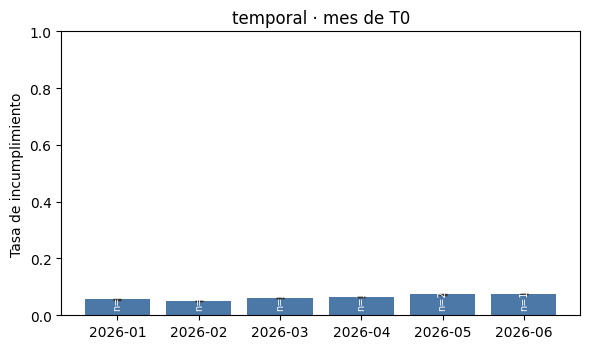

temporal · día de la semana


guias,n_etiquetadas,incumplidas,n_con_ultima_milla,mediana_h,p90_h,tasa_incumplimiento,ic95_inf,ic95_sup,pct_guias
99911,99911,5332,99909,6.061,12.8427,0.0534,0.052,0.0548,0.0849
241737,241737,13281,241735,5.9836,12.3084,0.0549,0.054,0.0559,0.2053
241735,241735,13684,241725,6.0218,12.2022,0.0566,0.0557,0.0575,0.2053
221321,221321,12478,221320,5.965,12.0158,0.0564,0.0554,0.0573,0.188
208281,208281,11662,208265,5.936,12.2692,0.056,0.055,0.057,0.1769
164266,164266,18189,164265,4.9874,36.2574,0.1107,0.1092,0.1123,0.1395
90,90,3,90,4.3107,9.2269,0.0333,0.0114,0.0935,1.0E-4


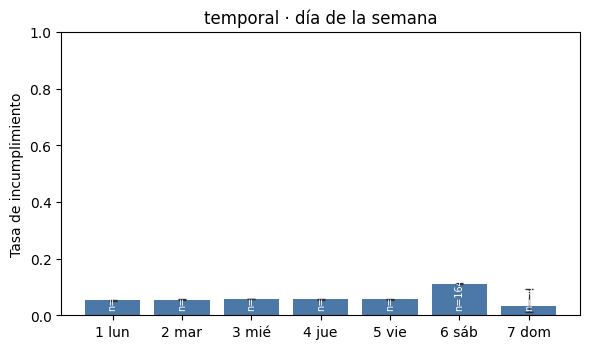

temporal · franja de T0


guias,n_etiquetadas,incumplidas,n_con_ultima_milla,mediana_h,p90_h,tasa_incumplimiento,ic95_inf,ic95_sup,pct_guias
46778,46778,6212,46778,9.8446,31.8995,0.1328,0.1298,0.1359,0.0397
1117804,1117804,65378,1117790,5.7176,12.0695,0.0585,0.0581,0.0589,0.9494
1049,1049,418,1049,13.4573,18.1714,0.3985,0.3693,0.4284,9.0E-4
11710,11710,2621,11692,6.2046,46.1354,0.2238,0.2164,0.2315,0.0099


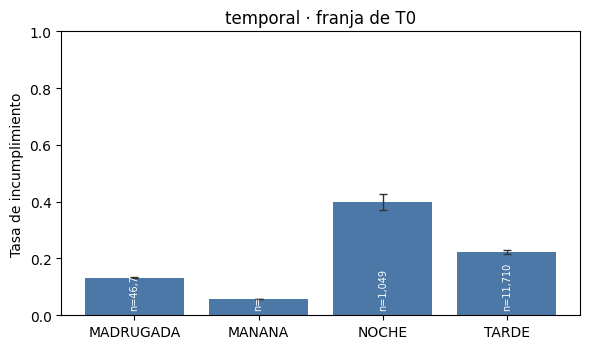

temporal · hora de T0


guias,n_etiquetadas,incumplidas,n_con_ultima_milla,mediana_h,p90_h,tasa_incumplimiento,ic95_inf,ic95_sup,pct_guias
91,91,2,91,16.6961,16.8498,0.022,0.006,0.0766,1.0E-4
452,452,42,452,11.6087,20.2761,0.0929,0.0695,0.1232,4.0E-4
4506,4506,450,4506,10.8171,28.2528,0.0999,0.0915,0.109,0.0038
21630,21630,2650,21630,9.8595,31.6105,0.1225,0.1182,0.127,0.0184
20098,20098,3068,20098,9.4301,32.4126,0.1527,0.1477,0.1577,0.0171
35243,35243,3642,35241,6.9742,28.1947,0.1033,0.1002,0.1066,0.0299
129891,129891,6808,129888,6.494,12.508,0.0524,0.0512,0.0536,0.1103
248967,248967,13667,248965,5.7916,12.3962,0.0549,0.054,0.0558,0.2115
376891,376891,17693,376887,5.2848,11.3272,0.0469,0.0463,0.0476,0.3201
282069,282069,17520,282068,5.6694,11.7945,0.0621,0.0612,0.063,0.2396


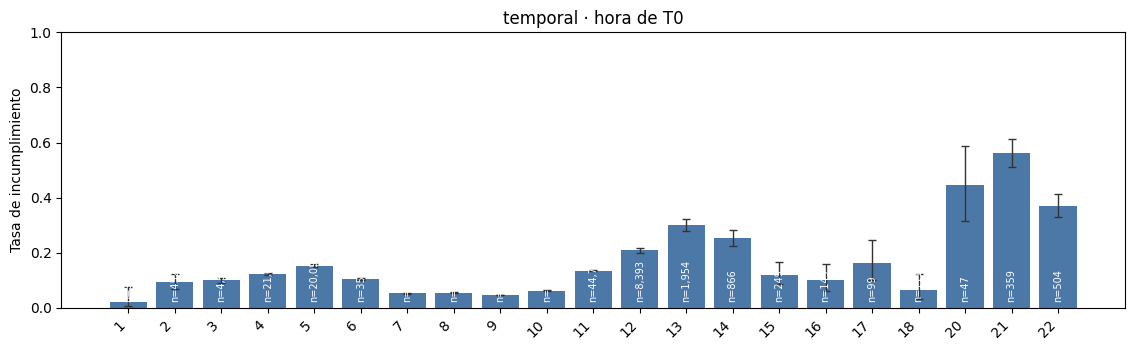

temporal · festivo


guias,n_etiquetadas,incumplidas,n_con_ultima_milla,mediana_h,p90_h,tasa_incumplimiento,ic95_inf,ic95_sup,pct_guias
75,75,0,75,5.9397,8.0358,0.0,0.0,0.0487,1.0E-4
1177266,1177266,74629,1177234,5.8517,12.5391,0.0634,0.063,0.0638,0.9999


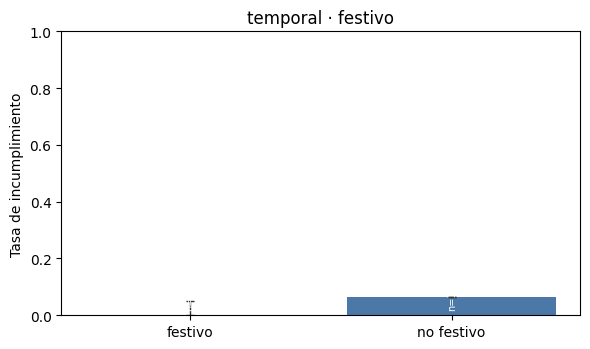

espacial · categoría de zona


guias,n_etiquetadas,incumplidas,n_con_ultima_milla,mediana_h,p90_h,tasa_incumplimiento,ic95_inf,ic95_sup,pct_guias
713479,713479,34019,713474,5.4382,11.4439,0.0477,0.0472,0.0482,0.606
3897,3897,24,3897,3.3467,5.698,0.0062,0.0041,0.0091,0.0033
126544,126544,4595,126525,5.7883,11.5271,0.0363,0.0353,0.0374,0.1075
5624,5624,4151,5623,52.1524,193.5929,0.7381,0.7264,0.7494,0.0048
212329,212329,13459,212322,6.0453,12.0875,0.0634,0.0624,0.0644,0.1803
115452,115452,18375,115452,8.5133,36.8289,0.1592,0.1571,0.1613,0.0981


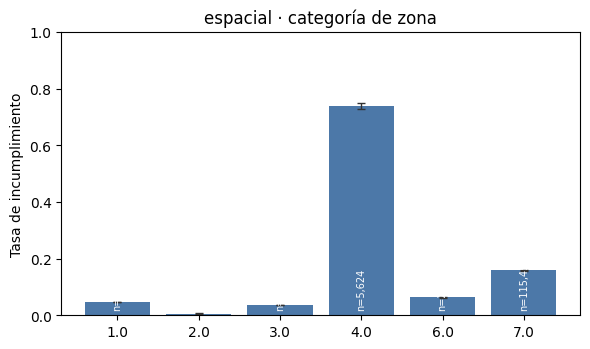

espacial · regional de origen


guias,n_etiquetadas,incumplidas,n_con_ultima_milla,mediana_h,p90_h,tasa_incumplimiento,ic95_inf,ic95_sup,pct_guias
101697,101697,6804,101695,5.4749,12.1569,0.0669,0.0654,0.0685,0.0864
361604,361604,26420,361583,6.2192,13.0946,0.0731,0.0722,0.0739,0.3071
30275,30275,2101,30274,5.7284,12.5448,0.0694,0.0666,0.0723,0.0257
102601,102601,5937,102600,5.4963,11.9068,0.0579,0.0565,0.0593,0.0871
29408,29408,2031,29408,5.5662,12.6224,0.0691,0.0662,0.072,0.025
143164,143164,7690,143162,5.5431,12.2617,0.0537,0.0526,0.0549,0.1216
75875,75875,4867,75874,5.3313,11.9948,0.0641,0.0624,0.0659,0.0644
63943,63943,4543,63943,5.5849,12.6318,0.071,0.0691,0.0731,0.0543
239680,239680,12488,239676,6.1547,12.3255,0.0521,0.0512,0.053,0.2036
29094,29094,1748,29094,5.4658,12.0064,0.0601,0.0574,0.0629,0.0247


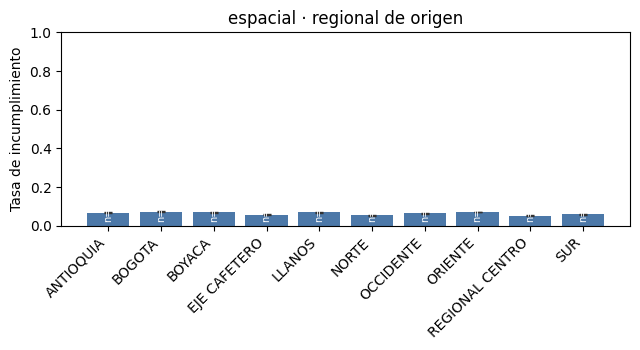

operación · piezas declaradas


guias,n_etiquetadas,incumplidas,n_con_ultima_milla,mediana_h,p90_h,tasa_incumplimiento,ic95_inf,ic95_sup,pct_guias
1149522,1149522,73402,1149502,5.8768,12.5839,0.0639,0.0634,0.0643,0.9764
11419,11419,582,11419,5.2239,10.7966,0.051,0.0471,0.0552,0.0097
8565,8565,310,8563,4.9961,9.8697,0.0362,0.0324,0.0404,0.0073
5493,5493,229,5483,4.1808,8.6734,0.0417,0.0367,0.0473,0.0047
2342,2342,106,2342,5.7193,11.5742,0.0453,0.0376,0.0545,0.002


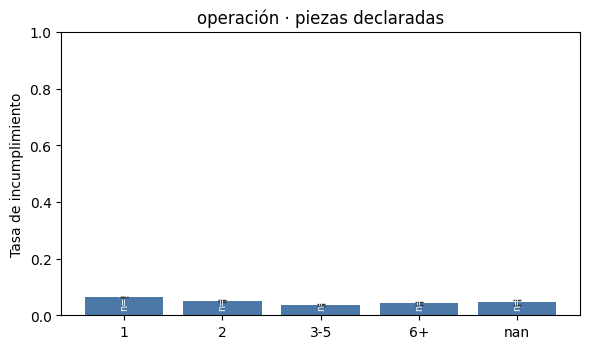

operación · decil de peso


guias,n_etiquetadas,incumplidas,n_con_ultima_milla,mediana_h,p90_h,tasa_incumplimiento,ic95_inf,ic95_sup,pct_guias
38323,38323,1834,38323,6.1834,12.3211,0.0479,0.0458,0.05,0.0326
81196,81196,4578,81182,5.5479,11.6369,0.0564,0.0548,0.058,0.069
66863,66863,3816,66863,6.2766,12.6025,0.0571,0.0553,0.0589,0.0568
66661,66661,4157,66661,6.3847,12.7669,0.0624,0.0605,0.0642,0.0566
51440,51440,2220,51440,6.0329,12.1144,0.0432,0.0414,0.0449,0.0437
77623,77623,4019,77623,6.1558,12.233,0.0518,0.0502,0.0534,0.0659
79581,79581,4653,79581,6.4536,12.6042,0.0585,0.0569,0.0601,0.0676
77361,77361,4649,77360,6.5092,12.6514,0.0601,0.0584,0.0618,0.0657
74232,74232,4696,74231,6.0639,12.5897,0.0633,0.0615,0.065,0.0631
69221,69221,4116,69220,5.8503,12.2361,0.0595,0.0577,0.0612,0.0588


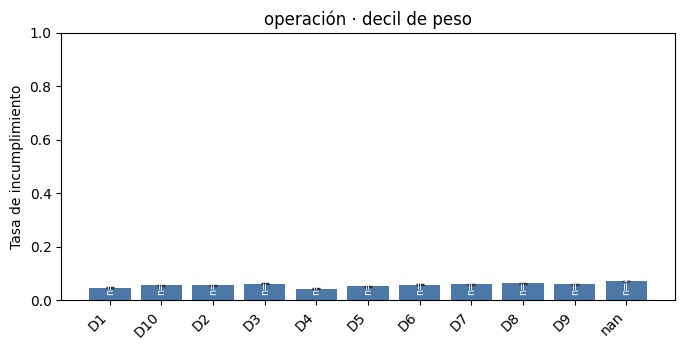

operación · re-despachos


guias,n_etiquetadas,incumplidas,n_con_ultima_milla,mediana_h,p90_h,tasa_incumplimiento,ic95_inf,ic95_sup,pct_guias
1127872,1127872,31869,1127841,5.6662,11.3052,0.0283,0.028,0.0286,0.958
44065,44065,37414,44064,51.6358,104.1856,0.8491,0.8457,0.8524,0.0374
4267,4267,4210,4267,104.903,223.322,0.9866,0.9827,0.9897,0.0036
842,842,841,842,169.9973,559.8253,0.9988,0.9933,0.9998,7.0E-4
190,190,190,190,251.9691,818.5394,1.0,0.9802,1.0,2.0E-4
72,72,72,72,299.5665,867.2529,1.0,0.9493,1.0,1.0E-4


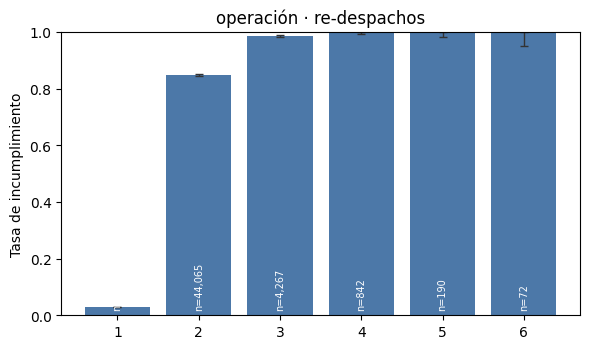

servicio · producto


guias,n_etiquetadas,incumplidas,n_con_ultima_milla,mediana_h,p90_h,tasa_incumplimiento,ic95_inf,ic95_sup,pct_guias
366499,366499,21756,366492,5.3481,12.2923,0.0594,0.0586,0.0601,0.3113
597488,597488,42740,597481,6.1768,12.9408,0.0715,0.0709,0.0722,0.5075
153833,153833,6217,153818,5.8157,11.7282,0.0404,0.0394,0.0414,0.1307
20001,20001,1151,20000,4.3766,11.5236,0.0575,0.0544,0.0609,0.017
4186,4186,140,4186,4.0748,9.8217,0.0334,0.0284,0.0393,0.0036
78,78,2,78,2.9541,7.843,0.0256,0.0071,0.0888,1.0E-4
30,30,1,30,5.8066,11.6747,0.0333,0.0059,0.1667,0.0
2311,2311,344,2311,7.0494,51.6947,0.1489,0.1349,0.1639,0.002
65,65,8,65,7.8966,93.952,0.1231,0.0637,0.2245,1.0E-4
2290,2290,159,2290,6.0298,12.3248,0.0694,0.0597,0.0806,0.0019


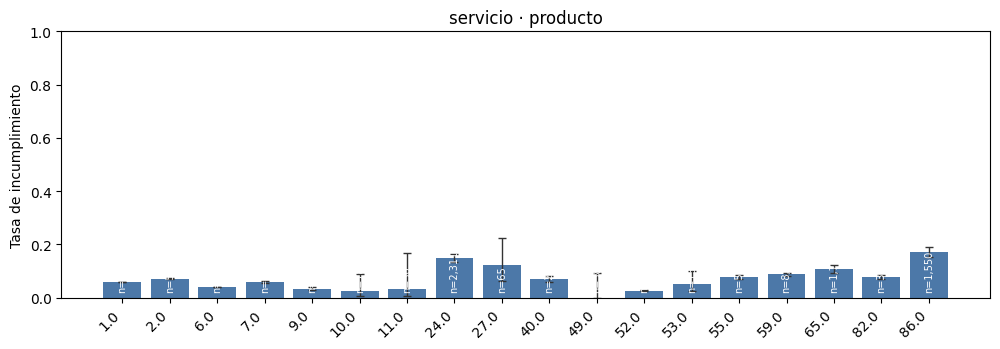

servicio · tipo de guía


guias,n_etiquetadas,incumplidas,n_con_ultima_milla,mediana_h,p90_h,tasa_incumplimiento,ic95_inf,ic95_sup,pct_guias
8339,8339,162,8337,4.6121,9.9395,0.0194,0.0167,0.0226,0.0071
12895,12895,996,12895,5.1779,12.4162,0.0772,0.0728,0.082,0.011
300,300,25,300,6.0155,14.7661,0.0833,0.0571,0.1201,3.0E-4
8161,8161,383,8161,6.2517,11.582,0.0469,0.0426,0.0517,0.0069
33119,33119,1880,33115,6.4513,12.7726,0.0568,0.0543,0.0593,0.0281
63756,63756,4471,63754,6.1242,12.853,0.0701,0.0682,0.0721,0.0542
110,110,6,110,5.4423,14.0486,0.0545,0.0252,0.1139,1.0E-4
8467,8467,631,8467,5.9052,12.8074,0.0745,0.0691,0.0803,0.0072
5708,5708,28,5707,3.536,9.6006,0.0049,0.0034,0.0071,0.0048
1355,1355,74,1355,5.8268,12.3212,0.0546,0.0437,0.068,0.0012


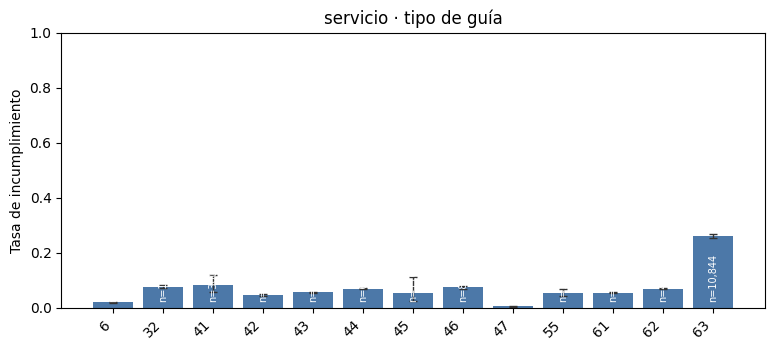

servicio · SLA comprometido (h)


guias,n_etiquetadas,incumplidas,n_con_ultima_milla,mediana_h,p90_h,tasa_incumplimiento,ic95_inf,ic95_sup,pct_guias
2976,2976,254,2976,3.8524,9.0749,0.0853,0.0758,0.0959,0.0025
972891,972891,63388,972860,5.8919,12.5465,0.0652,0.0647,0.0656,0.8263
172715,172715,9894,172714,5.6468,12.4765,0.0573,0.0562,0.0584,0.1467
15659,15659,686,15659,5.6953,12.5488,0.0438,0.0407,0.0471,0.0133
6755,6755,257,6755,5.9951,13.0316,0.038,0.0337,0.0429,0.0057
3705,3705,124,3705,6.0972,12.8754,0.0335,0.0281,0.0398,0.0031
1083,1083,11,1083,6.261,12.5037,0.0102,0.0057,0.0181,9.0E-4
505,505,7,505,7.1464,13.5712,0.0139,0.0067,0.0283,4.0E-4
1033,1033,6,1033,5.9114,12.0042,0.0058,0.0027,0.0126,9.0E-4


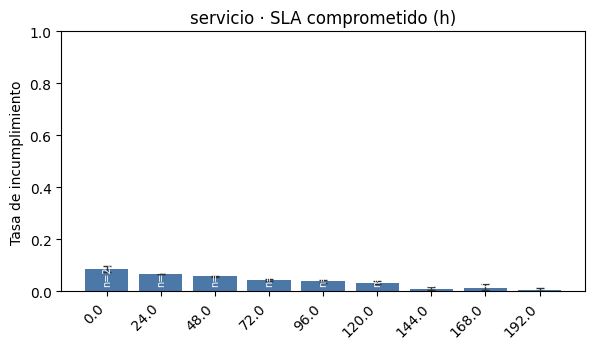

servicio · margen de SLA en T0 (h)


guias,n_etiquetadas,incumplidas,n_con_ultima_milla,mediana_h,p90_h,tasa_incumplimiento,ic95_inf,ic95_sup,pct_guias
443,443,384,443,13.26,16.0522,0.8668,0.832,0.8953,4.0E-4
1013990,1013990,68882,1013979,5.8426,12.5499,0.0679,0.0674,0.0684,0.8613
111131,111131,2178,111117,6.0173,11.8146,0.0196,0.0188,0.0204,0.0944
9596,9596,2474,9590,7.004,48.0069,0.2578,0.2492,0.2667,0.0082
42181,42181,711,42180,5.5268,12.8674,0.0169,0.0157,0.0181,0.0358


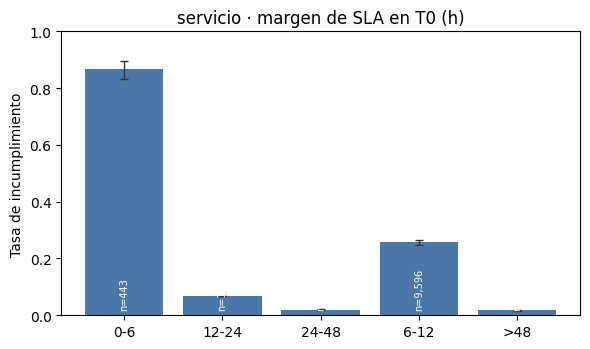

In [0]:
FACTORES = {
    "temporal · mes de T0": "mes_t0", "temporal · día de la semana": "dia_semana", "temporal · franja de T0": "franja",
    "temporal · hora de T0": "hora_t0", "temporal · festivo": "festivo_t0",
    "espacial · categoría de zona": "categoria_zona", "espacial · regional de origen": "regional_origen",
    "operación · piezas declaradas": "piezas_cat", "operación · decil de peso": "peso_decil",
    "operación · re-despachos": "n_salidas_zona",
    "servicio · producto": "ID_PRODUCTO", "servicio · tipo de guía": "ID_TIPOGUIA",
    "servicio · SLA comprometido (h)": "sla_h", "servicio · margen de SLA en T0 (h)": "margen_cat"}
perfiles = {}
for i, (titulo, col) in enumerate(FACTORES.items(), start=1):
    t = perfil(d, col); perfiles[col] = t
    print(titulo); display(t)
    guardar(t, f"04_{i:02d}_{col}")
    if 1 < len(t) <= 25:
        grafico_tasa(t, titulo, f"04_{i:02d}_{col}", rot=45 if len(t) > 8 else 0)

In [0]:
# Zonas urbanas: las 15 de mayor y menor tasa (con n >= N_MIN)
z = perfil(d, "zona_urbana", orden="tasa_incumplimiento")
display(pd.concat([z.head(15), z.tail(15)])); guardar(z, "04_zonas_urbanas")
print(f"{len(z)} zonas con al menos {N_MIN} guías; rango de tasas {z.tasa_incumplimiento.min():.2f}–{z.tasa_incumplimiento.max():.2f}")

guias,n_etiquetadas,incumplidas,n_con_ultima_milla,mediana_h,p90_h,tasa_incumplimiento,ic95_inf,ic95_sup,pct_guias
32,32,32,32,73.0169,170.6517,1.0,0.8928,1.0,0.0
45,45,45,45,31.3973,37.8988,1.0,0.9213,1.0,0.0
39,39,39,39,78.6389,137.5223,1.0,0.9103,1.0,0.0
37,37,36,37,118.7654,215.1098,0.973,0.8618,0.9952,0.0
53,53,51,53,126.5067,259.0892,0.9623,0.8725,0.9896,0.0
67,67,64,67,144.6001,257.4907,0.9552,0.8764,0.9847,1.0E-4
1055,1055,995,1055,54.4683,131.2059,0.9431,0.9275,0.9556,9.0E-4
31,31,29,31,126.9704,223.2893,0.9355,0.7928,0.9821,0.0
99,99,89,99,123.5861,253.2973,0.899,0.824,0.9442,1.0E-4
43,43,38,43,103.1858,263.3925,0.8837,0.7552,0.9493,0.0


519 zonas con al menos 30 guías; rango de tasas 0.00–1.00


## 5. Interacción zona × franja (mediana de horas de última milla)

MADRUGADA,MANANA,NOCHE,TARDE
13.0,5.4,0.4,4.5
null,3.3,null,null
9.0,5.8,0.1,2.8
35.1,52.9,null,50.7
7.7,6.0,null,9.5
9.8,7.6,13.6,26.0
null,null,null,null


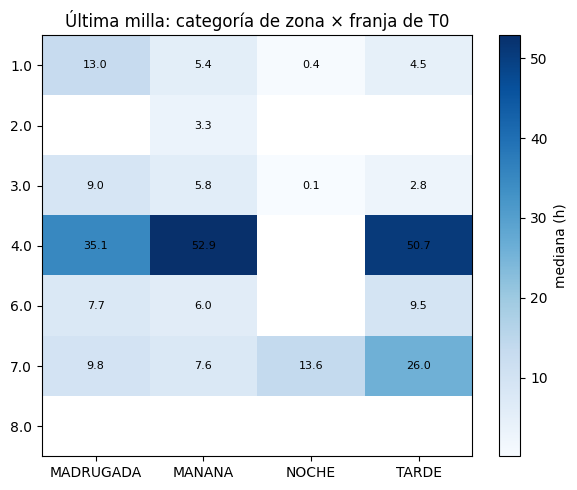

In [0]:
tab = d.pivot_table(index="categoria_zona", columns="franja", values="h_ultima_milla", aggfunc="median", observed=True)
cnt = d.pivot_table(index="categoria_zona", columns="franja", values="h_ultima_milla", aggfunc="count", observed=True)
tab = tab.where(cnt >= N_MIN)
display(tab.round(1)); guardar(tab.round(2), "05_zona_x_franja_mediana")
fig, ax = plt.subplots(figsize=(6, 0.5 * len(tab) + 1.5))
im = ax.imshow(tab.values, cmap="Blues", aspect="auto")
ax.set_xticks(range(tab.shape[1])); ax.set_xticklabels(tab.columns); ax.set_yticks(range(tab.shape[0])); ax.set_yticklabels(tab.index)
for i in range(tab.shape[0]):
    for j in range(tab.shape[1]):
        if pd.notna(tab.values[i, j]): ax.text(j, i, f"{tab.values[i, j]:.1f}", ha="center", va="center", fontsize=8)
plt.colorbar(im, label="mediana (h)"); ax.set_title("Última milla: categoría de zona × franja de T0")
plt.tight_layout(); fig.savefig(f"{CARPETA_EDA}05_zona_x_franja.png", dpi=130); plt.show()

## 6. Clima previo a T0 (solo si existe la base de 0160)

guias,n_etiquetadas,incumplidas,n_con_ultima_milla,mediana_h,p90_h,tasa_incumplimiento,ic95_inf,ic95_sup,pct_guias
253,253,18,253,5.2957,10.8893,0.0711,0.0455,0.1096,2.0E-4
298504,298504,18913,298491,5.8819,12.4883,0.0634,0.0625,0.0642,0.2543
555364,555364,36279,555349,5.81,12.6308,0.0653,0.0647,0.066,0.4731
303330,303330,18369,303327,5.8853,12.4425,0.0606,0.0597,0.0614,0.2584
16508,16508,834,16507,6.4222,12.1886,0.0505,0.0473,0.054,0.0141


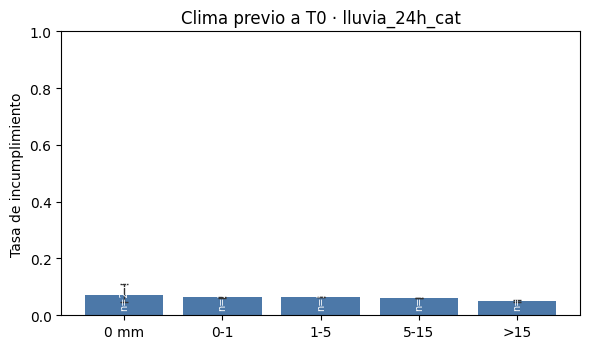

guias,n_etiquetadas,incumplidas,n_con_ultima_milla,mediana_h,p90_h,tasa_incumplimiento,ic95_inf,ic95_sup,pct_guias
596680,596680,34553,596670,5.8936,12.4139,0.0579,0.0573,0.0585,0.5083
15755,15755,926,15754,5.3931,12.3181,0.0588,0.0552,0.0626,0.0134
560206,560206,38788,560185,5.8352,12.6819,0.0692,0.0686,0.0699,0.4772
1318,1318,146,1318,5.3271,20.3676,0.1108,0.0949,0.1289,0.0011


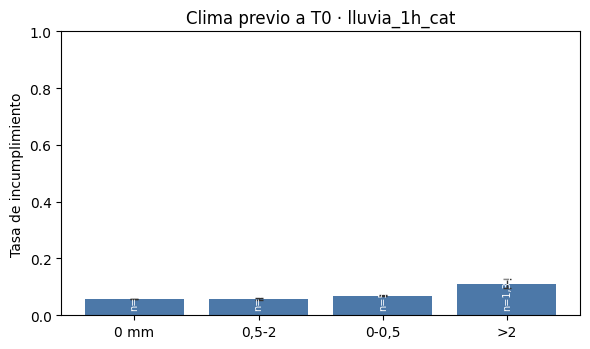

Guías con clima completo: 1,173,959 de 1,177,341. Lectura descriptiva: el clima es reanálisis retrospectivo.


In [0]:
if usa_clima:
    dc = d[d.CLIMA_COMPLETO.fillna(False).astype(bool)].copy()
    dc["lluvia_24h_cat"] = pd.cut(dc.LLUVIA_24H_PREV, [-0.01, 0.0, 1, 5, 15, np.inf],
                                  labels=["0 mm", "0-1", "1-5", "5-15", ">15"]).astype(str)
    dc["lluvia_1h_cat"] = pd.cut(dc.PRECIP_PREV_1H, [-0.01, 0.0, 0.5, 2, np.inf], labels=["0 mm", "0-0,5", "0,5-2", ">2"]).astype(str)
    for col in ["lluvia_24h_cat", "lluvia_1h_cat"]:
        t = perfil(dc, col); display(t); guardar(t, f"06_{col}")
        grafico_tasa(t, f"Clima previo a T0 · {col}", f"06_{col}")
    print(f"Guías con clima completo: {len(dc):,} de {len(d):,}. Lectura descriptiva: el clima es reanálisis retrospectivo.")
else:
    print("No existe la base con clima de 0160: sección omitida.")

## 7. Ordenamiento de factores por su relación con el retraso

Medidas univariadas y descriptivas, comparables entre factores:
- **Incumplimiento:** AUC de la tasa del grupo usada como puntaje (0,5 = sin relación). Los grupos con menos de `N_MIN` se agrupan en «OTROS».
- **Última milla:** razón de correlación η² (proporción de la varianza de las horas explicada por el grupo).

Para las variables continuas se usan sus categorías. No es una medida de importancia en un modelo multivariado (eso es 0420).

In [0]:
from sklearn.metrics import roc_auc_score
def eta2(y, g):
    m = y.groupby(g, observed=True).transform("mean")
    return float(((m - y.mean())**2).sum() / ((y - y.mean())**2).sum())
filas = []
candidatas = list(FACTORES.values()) + ["zona_urbana"] + (["lluvia_24h_cat"] if usa_clima else [])
base = dc if usa_clima else d
for col in candidatas:
    src = base if col.startswith("lluvia") else d
    g = src[col].astype(str)
    frec = g.map(g.value_counts()); g = g.where(frec >= N_MIN, "OTROS")
    e = src.incumplimiento_sla.notna()
    tasa = src.loc[e, "incumplimiento_sla"].groupby(g[e]).transform("mean")
    auc = roc_auc_score(src.loc[e, "incumplimiento_sla"], tasa) if src.loc[e, "incumplimiento_sla"].nunique() == 2 else np.nan
    r = src.h_ultima_milla.notna()
    filas.append({"factor": col, "categorias": g.nunique(), "AUC_incumplimiento": auc,
                  "eta2_ultima_milla": eta2(src.loc[r, "h_ultima_milla"], g[r]), "guias": len(src)})
rank = pd.DataFrame(filas).set_index("factor").sort_values("AUC_incumplimiento", ascending=False).round(4)
display(rank); guardar(rank, "07_ranking_factores")

categorias,AUC_incumplimiento,eta2_ultima_milla,guias
520,0.7873,0.0445,1177341
7,0.7836,0.1634,1177341
7,0.6348,0.0226,1177341
22,0.5961,0.0033,1177341
5,0.5624,0.0011,1177341
7,0.5588,9.0E-4,1177341
19,0.5506,6.0E-4,1177341
14,0.5496,7.0E-4,1177341
6,0.5423,3.0E-4,1177341
11,0.5408,3.0E-4,1177341


## Cómo leer y qué entregar

- `01_exclusiones`: si un motivo tiene una tasa de incumplimiento muy distinta de la general, excluirlo cambia la población; debe decirse en 4.2.2.
- `02_cuantiles_tiempos`: cifra para el documento («la mediana de última milla es X h»), siempre con su `n`.
- `04_*` y `05_*`: tablas del OE1 con denominador e IC. No interpretar diferencias cuyos IC se solapan.
- `07_ranking_factores`: insumo para la discusión del OE1 y para comparar con la interpretabilidad del modelo (0420).

**Entregar:** la carpeta `EDA/` completa (CSV y PNG). Ninguna salida contiene guías individuales.